This notebook shows how images can be created from phase and amplitude objects. First, import the necessary functions:


In [1]:
import sys
sys.path.append("../src/focalseriesrecon")

import numpy as np
from scipy.signal import convolve2d

from utils import *
from optics import *
from specimen import *

We can create a pure phase-object and a pure ampitude object:

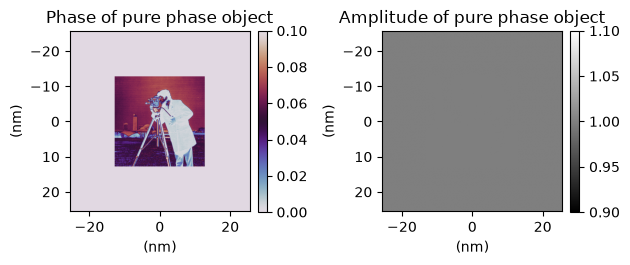

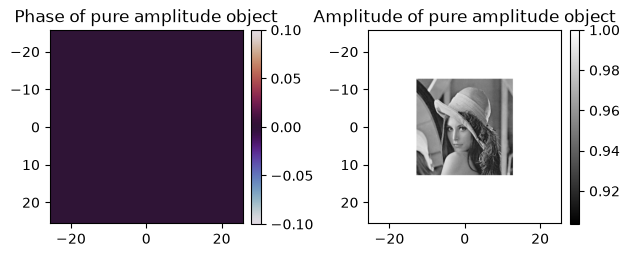

In [2]:
phase_obj = Specimen(phase_source='../images/cameraman512.jpg', phase_strength=0.1, resize_img=512, pixel_size=0.05)
amp_obj = Specimen(amp_source='../images/lena_1.jpg', amp_strength=0.1, resize_img=512, pixel_size=0.05)

fig, ax1 = plt.subplots(1, 2)
plot_2d(phase_obj.owf, x=phase_obj.x, y=phase_obj.y, mode="phase", title="Phase of pure phase object", xlabel="(nm)", ylabel="(nm)", ax=ax1[0])
plot_2d(phase_obj.owf, x=phase_obj.x, y=phase_obj.y, mode="abs", title="Amplitude of pure phase object", xlabel="(nm)", ylabel="(nm)", ax=ax1[1])
plt.tight_layout()

fig, ax2 = plt.subplots(1, 2)
plot_2d(amp_obj.owf, x=amp_obj.x, y=amp_obj.y, mode="phase", title="Phase of pure amplitude object", ax=ax2[0])
plot_2d(amp_obj.owf, x=amp_obj.x, y=amp_obj.y, mode="abs", title="Amplitude of pure amplitude object", ax=ax2[1])
plt.tight_layout()

The image wavefunctions are given by fourier transforming, applying the contrast transfer function, and inverse fourier transforming. We can either drop the nonlinear term, or keep it. First, we can generate the contrast transfer function:

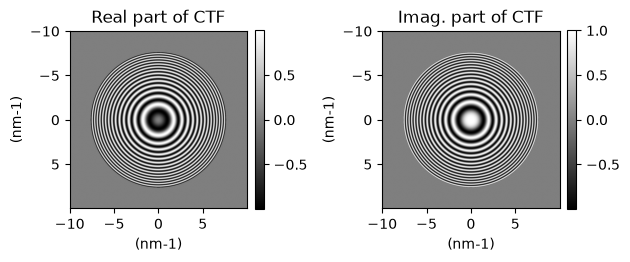

In [3]:
acc_voltage = 300
wavelength = electron_wavelength(acc_voltage)
cs=1e4
defocus=250
aperture_alpha_max=15

ctf_values_2d = ctf_complex(phase_obj.k_grid, wavelength, defocus, cs) * aperture_grid(phase_obj.k_grid, wavelength, aperture_alpha_max)
fig, ax3 = plt.subplots(1, 2)
plot_2d(ctf_values_2d, x=phase_obj.kx, y=phase_obj.ky, mode="imag", title="Real part of CTF", xlabel="(nm-1)", ylabel="(nm-1)", ax=ax3[0])
plot_2d(ctf_values_2d, x=phase_obj.kx, y=phase_obj.ky, mode="real", title="Imag. part of CTF", xlabel="(nm-1)", ylabel="(nm-1)", ax=ax3[1])
plt.tight_layout()

We can now generate the image wave functions by multiplying by the CTF in reciprocal space. The intensity is then found by taking the modulus squared. This can be done linearly, for small phases and amplitudes, or exact (nonlinear).

Text(0.5, 0.98, 'Amplitude object')

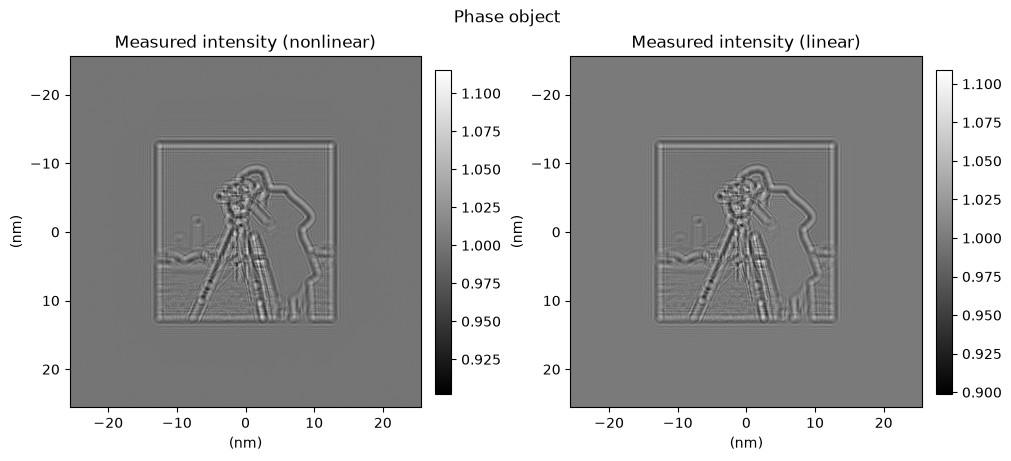

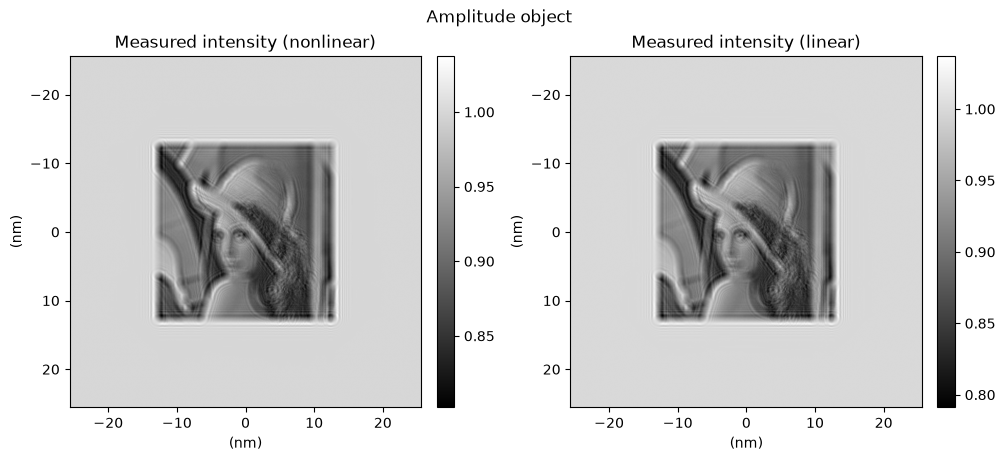

In [4]:
phase_obj_intensity_nonlinear = forward_nonlinear(phase_obj.owf, phase_obj.k_grid, wavelength, defocus, cs, aperture_alpha_max)
phase_obj_intensity_linear = forward_linear(phase_obj.owf, phase_obj.k_grid, wavelength, defocus, cs, aperture_alpha_max)
amp_obj_intensity_nonlinear = forward_nonlinear(amp_obj.owf, amp_obj.k_grid, wavelength, defocus, cs, aperture_alpha_max)
amp_obj_intensity_linear = forward_linear(amp_obj.owf, amp_obj.k_grid, wavelength, defocus, cs, aperture_alpha_max)

fig, ax4 = plt.subplots(1, 2, figsize=(10, 4.5), layout="constrained")
plot_2d(phase_obj_intensity_nonlinear, x=phase_obj.x, y=phase_obj.y, title="Measured intensity (nonlinear)", xlabel="(nm)", ylabel="(nm)", ax=ax4[0])
plot_2d(phase_obj_intensity_linear, x=phase_obj.x, y=phase_obj.y, title="Measured intensity (linear)", xlabel="(nm)", ylabel="(nm)", ax=ax4[1])
fig.suptitle("Phase object")

fig, ax5 = plt.subplots(1, 2, figsize=(10, 4.5), layout="constrained")
plot_2d(amp_obj_intensity_nonlinear, x=amp_obj.x, y=amp_obj.y, title="Measured intensity (nonlinear)", xlabel="(nm)", ylabel="(nm)", ax=ax5[0])
plot_2d(amp_obj_intensity_linear, x=amp_obj.x, y=amp_obj.y, title="Measured intensity (linear)", xlabel="(nm)", ylabel="(nm)", ax=ax5[1])
fig.suptitle("Amplitude object")

We can now also generate defocus series by doing what we have done multiple times for different defocus values. i will now only do the nonlinear image generation as that is the most physical way to generate data.

(<Figure size 1000x750 with 12 Axes>,
 array([<Axes: title={'center': 'Δf = 0nm'}>,
        <Axes: title={'center': 'Δf = 36nm'}>,
        <Axes: title={'center': 'Δf = 73nm'}>,
        <Axes: title={'center': 'Δf = 109nm'}>,
        <Axes: title={'center': 'Δf = 145nm'}>,
        <Axes: title={'center': 'Δf = 182nm'}>,
        <Axes: title={'center': 'Δf = 218nm'}>,
        <Axes: title={'center': 'Δf = 255nm'}>,
        <Axes: title={'center': 'Δf = 291nm'}>,
        <Axes: title={'center': 'Δf = 327nm'}>,
        <Axes: title={'center': 'Δf = 364nm'}>,
        <Axes: title={'center': 'Δf = 400nm'}>], dtype=object))

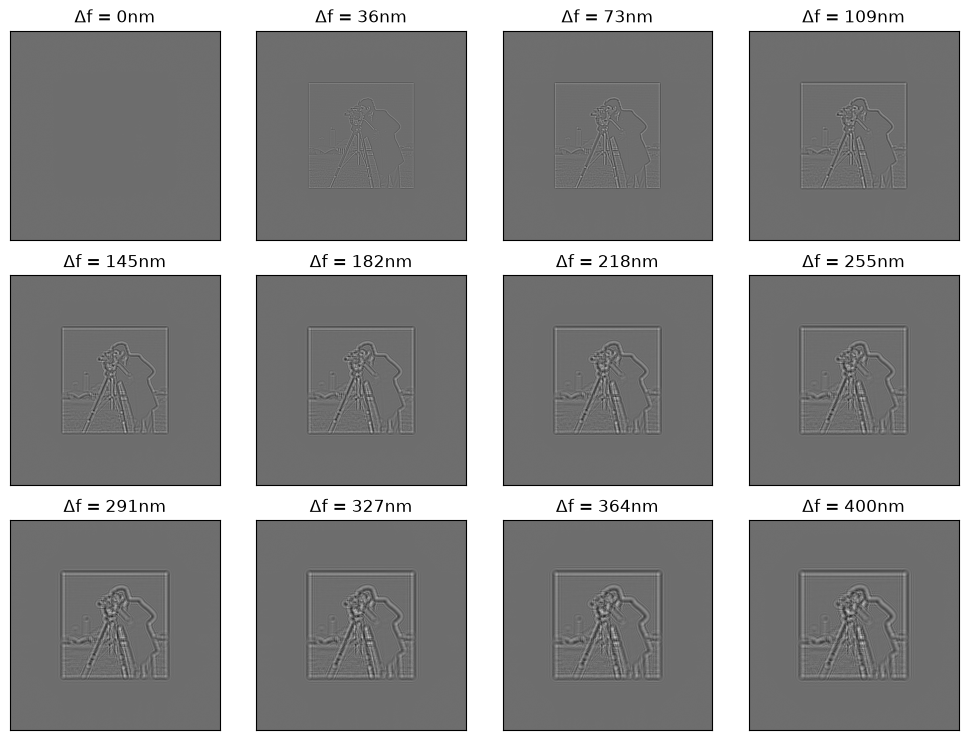

In [6]:
defoci = np.linspace(0, 400, 12)
phase_obj_focal_series = focal_series_nonlinear(defoci, phase_obj.owf, phase_obj.k_grid, wavelength, cs, aperture_alpha_max)

plot_focal_series(phase_obj_focal_series, defoci)